In [1]:
import numpy as np
import matplotlib.pyplot as plt

from results_loader import load_results

CONFIGS = {"GATAS_adaptive": "NSGA-II (reference)", "GATAS_dct": "+ DCT text", "GATAS_jac": "+ Jacobian basis",
           "GATAS_jacdct": "+ Jacobian + DCT", "GATAS_cmaes": "CMA-ES", "GATAS_mocma": "MO-CMA-ES",
           "GATAS_cmaes_jacdct": "CMA-ES + Jacobian + DCT", "GATAS_mocma_jacdct": "MO-CMA-ES + Jacobian + DCT"}
THRESHOLDS = {"PESQ": 0.2, "SET_OVERLAP": 0.5}
records = load_results("../outputs/results", dataset="harvard", asr_model="whisper-tiny", methods=list(CONFIGS))
configs = [c for c in CONFIGS if records[c]]

## RQ0 table and figure
All design variants on the sentences with a correct clean transcription (300 queries, one seed).

In [2]:
import pandas as pd
from scipy.stats import wilcoxon

ALL = {"GATAS_scale_0.5": "fixed 0.5", "GATAS_scale_1": "fixed 1", "GATAS_scale_2": "fixed 2", **CONFIGS}
rec = load_results("../outputs/results", dataset="harvard", asr_model="whisper-tiny", methods=list(ALL), exclude_original_fails=True)

rows = {}
for m, name in ALL.items():
    rs = rec[m]
    rows[name] = {"n": len(rs), "found": sum(r["success"] for r in rs), "UTMOS": np.mean([r["utmos"] for r in rs]),
                  "spectrogram": np.mean([r["spectrogram"] for r in rs]), "WER": np.mean([r["wer"] for r in rs]),
                  "mean scale": np.mean([r["scale"] for r in rs if r.get("scale") is not None] or [np.nan])}
rq0 = pd.DataFrame(rows).T
display(rq0.round(3))

ref = {r["sentence_id"]: r for r in rec["GATAS_adaptive"]}
fin = {r["sentence_id"]: r for r in rec["GATAS_cmaes_jacdct"]}
ids = sorted(set(ref) & set(fin))
for key in ["utmos", "wer", "spectrogram"]:
    print(f"final vs. reference, {key}: Wilcoxon p = {wilcoxon([fin[i][key] for i in ids], [ref[i][key] for i in ids]).pvalue:.4f} (uncorrected, n={len(ids)})")

,n,found,UTMOS,spectrogram,WER,mean scale
fixed 0.5,14.0,1.0,4.391,0.025,0.009,0.500
fixed 1,14.0,5.0,4.372,0.047,0.047,1.000
fixed 2,14.0,14.0,4.210,0.071,0.232,2.000
NSGA-II (reference),14.0,14.0,3.785,0.091,0.439,2.192
+ DCT text,14.0,13.0,3.989,0.080,0.214,1.640
+ Jacobian basis,14.0,14.0,3.771,0.082,0.380,2.338
+ Jacobian + DCT,14.0,14.0,3.989,0.078,0.320,1.876
CMA-ES,14.0,13.0,4.173,0.074,0.172,1.327
MO-CMA-ES,14.0,14.0,3.630,0.096,0.440,1.909
CMA-ES + Jacobian + DCT,14.0,14.0,4.232,0.072,0.135,1.265


final vs. reference, utmos: Wilcoxon p = 0.0085 (uncorrected, n=14)
final vs. reference, wer: Wilcoxon p = 0.0077 (uncorrected, n=14)
final vs. reference, spectrogram: Wilcoxon p = 0.0419 (uncorrected, n=14)


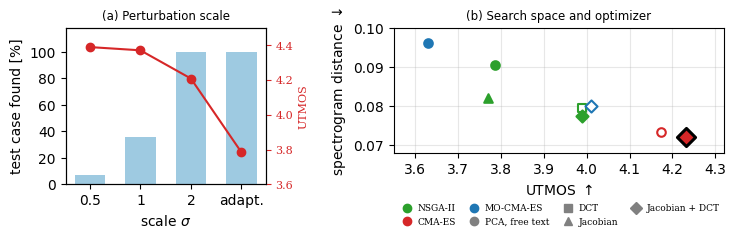

In [3]:
fig = plt.figure(figsize=(7.2, 2.3))
ax_a = fig.add_axes([0.065, 0.2, 2.0 / 7.2, 0.68])
ax_b = fig.add_axes([3.75 / 7.2, 0.2 + 0.2 * 0.68, 3.3 / 7.2, 0.8 * 0.68])
with plt.rc_context({"font.size": 8, "font.family": "serif"}):
    scale = [("0.5", "GATAS_scale_0.5"), ("1", "GATAS_scale_1"), ("2", "GATAS_scale_2"), ("adapt.", "GATAS_adaptive")]
    labels = [l for l, _ in scale]
    ax_a.bar(labels, [100 * rows[ALL[k]]["found"] / rows[ALL[k]]["n"] for _, k in scale], color="#9ecae1", width=0.6)
    ax_a.set_ylabel("test case found [%]"); ax_a.set_xlabel("scale $\\sigma$"); ax_a.set_ylim(0, 118)
    ax_a.set_title("(a) Perturbation scale", fontsize=8.5)
    twin = ax_a.twinx()
    twin.plot(labels, [rows[ALL[k]]["UTMOS"] for _, k in scale], "o-", color="#d62728")
    twin.set_ylabel("UTMOS", color="#d62728"); twin.set_ylim(3.6, 4.5); twin.tick_params(axis="y", colors="#d62728")

    from matplotlib.lines import Line2D
    OPT = {"NSGA-II": "#2ca02c", "CMA-ES": "#d62728", "MO-CMA-ES": "#1f77b4"}
    SPACE = {"PCA, free text": "o", "DCT": "s", "Jacobian": "^", "Jacobian + DCT": "D"}
    variants = {"GATAS_adaptive": ("NSGA-II", "PCA, free text"), "GATAS_dct": ("NSGA-II", "DCT"), "GATAS_jac": ("NSGA-II", "Jacobian"),
                "GATAS_jacdct": ("NSGA-II", "Jacobian + DCT"), "GATAS_cmaes": ("CMA-ES", "PCA, free text"),
                "GATAS_cmaes_jacdct": ("CMA-ES", "Jacobian + DCT"), "GATAS_mocma": ("MO-CMA-ES", "PCA, free text"),
                "GATAS_mocma_jacdct": ("MO-CMA-ES", "Jacobian + DCT")}
    BEST = "GATAS_cmaes_jacdct"
    for k, (opt, space) in variants.items():
        r = rows[CONFIGS[k]]
        full = r["found"] == r["n"]
        color = OPT[opt]
        ax_b.scatter(r["UTMOS"], r["spectrogram"], s=85 if k == BEST else 38, marker=SPACE[space],
                     facecolor=color if full else "white", edgecolor="black" if k == BEST else color,
                     linewidth=2.2 if k == BEST else 1.5, zorder=4 if k == BEST else 3)
    ax_b.set_xlabel("UTMOS $\\uparrow$"); ax_b.set_ylabel("spectrogram distance $\\downarrow$"); ax_b.grid(alpha=0.3)
    ax_b.set_xlim(3.55, 4.32); ax_b.set_ylim(0.068, 0.1)
    ax_b.set_title("(b) Search space and optimizer", fontsize=8.5)
    handles = [Line2D([], [], marker="o", ls="", color=c, label=o) for o, c in OPT.items()]
    handles += [Line2D([], [], marker=m, ls="", color="gray", label=sp) for sp, m in SPACE.items()]
    ax_b.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.34), ncol=4, frameon=False, handletextpad=0.2, columnspacing=1.0, fontsize=6.5)
    fig.savefig("_figures/rq0_ablation.pdf", bbox_inches="tight")
    plt.show()

### Selection ablation (intent)
Balanced vs. intent-first selection and margin objective on the commands with a correct clean intent.

In [4]:
SEL = {"GATAS_intent": "1-P(target), balanced selection", "GATAS_intent_sel": "1-P(target), intent-first selection",
       "GATAS_intent_margin": "margin objective, balanced selection", "GATAS_intent_margin_sel": "margin objective, intent-first selection"}
irec = load_results("../outputs/results", dataset="commands", asr_model="whisper-tiny", methods=list(SEL))
ids = {r["sentence_id"] for r in irec["GATAS_intent_sel"]}
sel_rows = {}
for m, name in SEL.items():
    rs = [r for r in irec[m] if r["sentence_id"] in ids and r["intent"]["original_correct"]]
    sel_rows[name] = {"n": len(rs), "changed": sum(r["intent"]["changed"] for r in rs), "target hit": sum(r["intent"]["target_match"] for r in rs),
                      "WER": round(np.mean([r["wer"] for r in rs]), 2), "UTMOS": round(np.mean([r["utmos"] for r in rs]), 2)}
display(pd.DataFrame(sel_rows).T)

,n,changed,target hit,WER,UTMOS
"1-P(target), balanced selection",19.0,4.0,0.0,0.29,4.15
"1-P(target), intent-first selection",19.0,10.0,2.0,0.51,3.56
"margin objective, balanced selection",19.0,4.0,0.0,0.27,4.15
"margin objective, intent-first selection",19.0,10.0,2.0,0.49,3.57
